<a href="https://colab.research.google.com/github/nkhanhhh/uplift-prediction-models-for-online-advertising/blob/main/DESCN_Criteo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TARNet, CFR, DESCN và hai cải tiến trên dữ liệu Criteo (mã nguồn chính thức của paper DESCN)

Notebook đi kèm `Uplift_Benchmark_Criteo.ipynb`. Mạng nơ-ron chạy bằng **repo chính thức của paper DESCN** (Zhong và cs., KDD 2022; https://github.com/kailiang-zhong/DESCN, PyTorch). Repo này cài sẵn cả TARNet và CFR (Shalit và cs., 2017).

| | |
|---|---|
| **Bản gốc (thư mục `DESCN`)** | Giữ nguyên toàn bộ mã và tham số trong file cấu hình có sẵn cho dữ liệu Lazada (`conf4models/lzd_real_data/`). Chỉ đổi thiết lập chạy: đường dẫn dữ liệu; thiết bị (cấu hình gốc là `cuda:1`, Colab chỉ có `cuda:0`); `n_experiments = 1`; `val_rate = 0` (học trên đúng tập train như các giải thuật ở notebook kia) |
| **Bản sửa (thư mục `DESCN_cai_tien`, phần tự viết)** | Sao chép từ bản gốc rồi sửa ở mục 4b. **Cải tiến P** (tuần 5): cân bằng lại hàm mất mát propensity của DESCN. **Cải tiến A3** (tuần 7): thêm đầu ra visit và ràng buộc phễu cho TARNet. Mọi thay đổi đều có cờ trong file cấu hình; cờ tắt thì bản sửa cho kết quả trùng bản gốc (mục 4b kiểm tra) |
| **Đánh giá** | Cùng mẫu dữ liệu, cùng cách chia, cùng hàm đánh giá với notebook benchmark; lấy dự đoán ở epoch cuối. Không dùng `eval4real_data.py` của repo vì script này giữ lại epoch có AUUC cao nhất trên chính tập test |
| **Tiêu chí cải tiến** | Qini AUC cao hơn bản gốc ở ít nhất 4/5 seed và khoảng tin cậy bootstrap 95% của chênh lệch nằm hẳn trên 0 (mục 9) |

**Cách chạy:** *Runtime → Change runtime type → GPU (T4)*, rồi *Runtime → Run all*. Đặt `TUAN` ở mục 2 theo tuần đang làm: `5` = TARNet, CFR, DESCN và cải tiến P; `7` = thêm A3; `8` = thêm các thí nghiệm loại trừ và phân tích theo cỡ mẫu. Phải dùng cùng `N_SAMPLE`, `SEEDS`, `VAL_SIZE`, `TEST_SIZE`, `DATA_PATH` với notebook benchmark; mục 7 in "mã tập test" để đối chiếu. Lần đầu đặt `QUICK_RUN = True` để thử toàn bộ code (khoảng 15 phút). Cấu hình đầy đủ: tuần 5 khoảng 1–1,5 giờ trên GPU T4; tuần 7 thêm khoảng 15 phút; tuần 8 thêm khoảng 1 giờ. Kết quả lưu sau mỗi lần chạy nên bị ngắt thì chạy lại để làm tiếp.

| Mục | Nội dung | Tuần |
|---|---|---|
| 1–4 | Chuẩn bị repo, cấu hình, hàm đánh giá, hàm gọi mã nguồn của repo | 5 |
| 4b | Bản sửa của repo cho hai cải tiến; kiểm tra cờ tắt = bản gốc | 5, 7 |
| 5 | Kiểm tra trên dữ liệu mô phỏng có uplift thật | 5, 7 |
| 6–7 | Tải dữ liệu, chia giống notebook benchmark, chạy trên Criteo | 5, 7, 8 |
| 8 | Bảng so sánh đầy đủ 11 giải thuật gốc | 5 |
| 9 | Đối chiếu tiêu chí: cải tiến so với bản gốc; thí nghiệm loại trừ | 5, 7, 8 |

## 1. Chuẩn bị: GPU, thư viện, mã nguồn của repo
Tải repo về đúng commit đã thử để chạy lại được. Ô này in GPU, phiên bản thư viện và commit của repo (minh chứng Hình 5.1).

In [ ]:
import os, sys, shutil, subprocess
print(subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True).stdout.strip()
      if shutil.which("nvidia-smi") else "Không thấy GPU: Runtime → Change runtime type → GPU, rồi chạy lại")

%pip install -q kagglehub geomloss hydra-core tensorboard scikit-uplift==0.5.1

REPO_URL = "https://github.com/kailiang-zhong/DESCN.git"
COMMIT   = "80fd11e02d05af241eeaf67d701be599da528cb1"     # commit mới nhất của repo khi lập kế hoạch (27/12/2023)
REPO_DIR = os.path.abspath("DESCN")
if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "-q", REPO_URL, REPO_DIR], check=True)
subprocess.run(["git", "-C", REPO_DIR, "checkout", "-q", COMMIT], check=True)
head = subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--format=%h (%cd)", "--date=short"],
                      capture_output=True, text=True).stdout.strip()
print("Repo:", REPO_URL, "| commit", head)

from importlib.metadata import version
print("Python", sys.version.split()[0], "|", " | ".join(
    f"{p} {version(p)}" for p in ["torch", "numpy", "pandas", "scikit-learn", "hydra-core", "geomloss", "scikit-uplift"]))

GPU 0: Tesla T4 (UUID: GPU-624f49a4-7349-0b51-81f3-c5ad2ecc0dc2)
Repo: https://github.com/kailiang-zhong/DESCN.git | commit 80fd11e (2023-12-27)
Python 3.13.15 | torch 2.11.0+cu130 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | hydra-core 1.3.7 | geomloss 0.3.1 | scikit-uplift 0.5.1


## 2. Cấu hình
- `TUAN`: tuần đang làm, quyết định chạy những mô hình nào (cột `week` trong `NETS`).
- Các giá trị từ `N_SAMPLE` đến `DATA_PATH` phải giống notebook benchmark.
- `NETS`: mỗi mô hình gồm repo (`goc` = bản gốc, `sua` = bản đã sửa), file cấu hình có sẵn trong repo, tham số đổi thêm (`extra`), tuần bắt đầu chạy, outcome áp dụng, và tỷ lệ tập train (`frac`, dùng cho phân tích theo cỡ mẫu).
- `OVERRIDES` để trống nghĩa là giữ nguyên tham số gốc. Nếu đổi tham số thì chỉ chọn trên tập validation (mục 10). Nếu đổi `OVERRIDES` hoặc cỡ mẫu, đổi tên thư mục `results` cũ trước khi chạy lại (vì `RESUME = True` bỏ qua các lần chạy đã có).

In [ ]:
import time, glob, gzip, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
import torch

warnings.filterwarnings("ignore")

TUAN      = 5      # 5: TARNet, CFR, DESCN và cải tiến P | 7: thêm A3 | 8: thêm thí nghiệm loại trừ, cỡ mẫu
QUICK_RUN = False  # True = chạy thử toàn bộ code (mẫu nhỏ, 1 seed, 1 epoch); KHÔNG dùng số liệu này cho báo cáo
OUTCOMES  = ["visit", "conversion"]
N_SAMPLE  = {"visit": 1_000_000, "conversion": 4_000_000}
SEEDS     = [0, 1, 2, 3, 4]
VAL_SIZE, TEST_SIZE = 0.2, 0.3
DATA_PATH = None
USE_DRIVE = True
RESUME    = True
N_BOOT    = 200
DEVICE    = "cuda:0" if torch.cuda.is_available() else "cpu"
OVERRIDES = {}

A3 = {"funnel_w": 1, "funnel_product": 1}          # cải tiến A3: trọng số loss visit = 1, có ràng buộc phễu
NETS = {
    "TARNet":   dict(repo="goc", conf="TARNet.txt", week=5),
    "CFR-WASS": dict(repo="goc", conf="CFRwass.txt", week=5),
    "DESCN":    dict(repo="goc", conf="DESCN.txt", week=5),
    "P: DESCN cân bằng propensity": dict(repo="sua", conf="DESCN.txt", extra={"prpsy_balance": 1}, week=5),
    "A3: TARNet + phễu": dict(repo="sua", conf="TARNet.txt", extra=A3, week=7, outcomes=["conversion"]),
    # Tuần 8 – thí nghiệm loại trừ cho A3
    "A3 không nhân phễu": dict(repo="sua", conf="TARNet.txt", extra={"funnel_w": 1, "funnel_product": 0},
                               week=8, outcomes=["conversion"]),
    "A3 (λ = 0,2)": dict(repo="sua", conf="TARNet.txt", extra={"funnel_w": 0.2, "funnel_product": 1},
                         week=8, outcomes=["conversion"]),
    "A3 (λ = 0,5)": dict(repo="sua", conf="TARNet.txt", extra={"funnel_w": 0.5, "funnel_product": 1},
                         week=8, outcomes=["conversion"]),
    "A3 (λ = 2)":   dict(repo="sua", conf="TARNet.txt", extra={"funnel_w": 2, "funnel_product": 1},
                         week=8, outcomes=["conversion"]),
}
SIZE_FRACTIONS = [0.25, 0.5]                        # tuần 8: TARNet và A3 học trên 25%, 50% tập train
for frac in SIZE_FRACTIONS:
    NETS[f"TARNet [{frac:.0%} train]"] = dict(repo="goc", conf="TARNet.txt", frac=frac, week=8, outcomes=["conversion"])
    NETS[f"A3: TARNet + phễu [{frac:.0%} train]"] = dict(repo="sua", conf="TARNet.txt", extra=A3, frac=frac,
                                                         week=8, outcomes=["conversion"])

if QUICK_RUN:
    TUAN = 8
    N_SAMPLE = {"visit": 200_000, "conversion": 400_000}
    SEEDS = [0]
    OVERRIDES = {"epochs": 1}
    N_BOOT = 20

def nets_for(outcome):
    return [n for n, c in NETS.items() if c["week"] <= TUAN and outcome in c.get("outcomes", ["visit", "conversion"])]

FEATURES = [f"f{i}" for i in range(12)]
LABELS   = ["treatment", "conversion", "visit", "exposure"]
WORK_DIR = os.path.abspath("descn_work")      # file npz, log và dự đoán của repo (tạo lại được, không cần lưu)
os.makedirs(WORK_DIR, exist_ok=True)

PROJECT_DIR = "."
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        PROJECT_DIR = "/content/drive/MyDrive/uplift_project"
    except ImportError:
        print("Không chạy trên Colab: lưu kết quả vào thư mục hiện tại")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results_quick" if QUICK_RUN else "results")
FIG_DIR     = os.path.join(PROJECT_DIR, "figures_quick" if QUICK_RUN else "figures")
PRED_DIR    = os.path.join(RESULTS_DIR, "preds")      # dự đoán trên tập test của seed đầu tiên (để vẽ hình)
for folder in (RESULTS_DIR, FIG_DIR, PRED_DIR):
    os.makedirs(folder, exist_ok=True)
print("Kết quả lưu tại:", os.path.abspath(RESULTS_DIR))

print("Cấu hình:", {"TUAN": TUAN, "QUICK_RUN": QUICK_RUN, "N_SAMPLE": N_SAMPLE, "SEEDS": SEEDS, "DEVICE": DEVICE})
print("Mô hình chạy:", {o: nets_for(o) for o in OUTCOMES})

Mounted at /content/drive
Kết quả lưu tại: /content/drive/MyDrive/uplift_project/results
Cấu hình: {'TUAN': 5, 'QUICK_RUN': False, 'N_SAMPLE': {'visit': 1000000, 'conversion': 4000000}, 'SEEDS': [0, 1, 2, 3, 4], 'DEVICE': 'cuda:0'}
Mô hình chạy: {'visit': ['TARNet', 'CFR-WASS', 'DESCN', 'P: DESCN cân bằng propensity'], 'conversion': ['TARNet', 'CFR-WASS', 'DESCN', 'P: DESCN cân bằng propensity']}


## 3. Hàm đánh giá
Giống hệt notebook benchmark (cùng được sinh từ một nguồn).

In [ ]:
from sklearn.metrics import auc

def _cumulative(y, t, score):
    # Cộng dồn theo uplift dự đoán giảm dần; các điểm có cùng score được gộp lại
    order = np.argsort(-score, kind="mergesort")
    y, t, score = y[order].astype(float), t[order].astype(float), score[order]
    ends = np.r_[np.flatnonzero(np.diff(score)), len(score) - 1]
    n = ends + 1.0
    n_t = np.cumsum(t)[ends]
    y_t = np.cumsum(y * t)[ends]
    y_c = np.cumsum(y * (1 - t))[ends]
    return n, n_t, n - n_t, y_t, y_c

def _div(a, b):
    return np.divide(a, b, out=np.zeros_like(a), where=b != 0)

def qini_curve(y, t, score):
    n, n_t, n_c, y_t, y_c = _cumulative(y, t, score)
    return np.r_[0, n], np.r_[0, y_t - y_c * _div(n_t, n_c)]

def uplift_curve(y, t, score):
    n, n_t, n_c, y_t, y_c = _cumulative(y, t, score)
    return np.r_[0, n], np.r_[0, (_div(y_t, n_t) - _div(y_c, n_c)) * n]

def _normalized_area(curve, y, t, score, perfect_score):
    x, v = curve(y, t, score)
    xp, vp = curve(y, t, perfect_score)
    random_area = auc([0, xp[-1]], [0, vp[-1]])
    return (auc(x, v) - random_area) / (auc(xp, vp) - random_area)

def qini_auc_score(y, t, score):
    perfect = y * t - y * (1 - t)
    return _normalized_area(qini_curve, y, t, score, perfect.astype(float))

def uplift_auc_score(y, t, score):
    ctrl_resp = np.sum((y == 1) & (t == 0))
    treat_nonresp = np.sum((y == 0) & (t == 1))
    perfect = 2 * (y == t) + (y if ctrl_resp > treat_nonresp else t)
    return _normalized_area(uplift_curve, y, t, score, perfect.astype(float))

def uplift_at_k(y, t, score, k):
    # Thứ tự khi trùng điểm giống scikit-uplift để hai bên cho cùng kết quả
    top = np.argsort(score, kind="mergesort")[::-1][: int(len(score) * k)]
    return y[top][t[top] == 1].mean() - y[top][t[top] == 0].mean()

def uplift_by_decile(y, t, score, n_bins=10):
    # Uplift thực tế (treatment − control) và uplift dự đoán trong từng nhóm 10% khách
    d = pd.DataFrame({"y": y, "t": t, "score": score})
    d["decile"] = pd.qcut(d["score"].rank(method="first", ascending=False), n_bins, labels=False) + 1
    g1, g0 = d[d.t == 1].groupby("decile")["y"], d[d.t == 0].groupby("decile")["y"]
    out = pd.DataFrame({"n_treatment": g1.size(), "n_control": g0.size(),
                        "rate_treatment": g1.mean(), "rate_control": g0.mean()})
    out["actual_uplift"] = out.rate_treatment - out.rate_control
    out["actual_uplift_se"] = np.sqrt(out.rate_treatment * (1 - out.rate_treatment) / out.n_treatment
                                      + out.rate_control * (1 - out.rate_control) / out.n_control)
    out["predicted_uplift"] = d.groupby("decile")["score"].mean()
    return out.rename_axis("decile").reset_index()

def evaluate(y, t, score):
    # Các chỉ số trên một tập (thường là tập test); score phải là mảng 1 chiều
    score = np.asarray(score, dtype=float).ravel()
    assert score.shape[0] == len(y), "score phải là mảng 1 chiều, cùng số dòng với y"
    return {"qini_auc": qini_auc_score(y, t, score), "auuc": uplift_auc_score(y, t, score),
            "uplift_at_10": uplift_at_k(y, t, score, 0.1), "uplift_at_20": uplift_at_k(y, t, score, 0.2),
            "uplift_at_30": uplift_at_k(y, t, score, 0.3)}

def summarize(res, metrics=("qini_auc", "auuc", "uplift_at_10")):
    # Bảng trung bình ± độ lệch chuẩn qua các seed
    g = res.groupby(["outcome", "model"])[list(metrics)]
    mean, std = g.mean(), g.std(ddof=1)
    out = mean.copy().astype(object)
    for m in metrics:
        out[m] = [f"{a:.4f} ± {b:.4f}" if pd.notna(b) else f"{a:.4f}" for a, b in zip(mean[m], std[m])]
    out["n_seeds"] = g.size()
    return out

def compare(res, outcome, model_a, model_b, metric="qini_auc"):
    # So sánh cặp theo từng seed
    a = res[(res.outcome == outcome) & (res.model == model_a)].set_index("seed")[metric]
    b = res[(res.outcome == outcome) & (res.model == model_b)].set_index("seed")[metric]
    d = (a - b).dropna()
    p = stats.ttest_rel(a[d.index], b[d.index]).pvalue if len(d) > 1 else np.nan
    return {"outcome": outcome, "A": model_a, "B": model_b, "metric": metric, "mean_diff": d.mean(),
            "wins_A": int((d > 0).sum()), "n_seeds": len(d), "p_value": p}

def bootstrap_diff(y, t, score_a, score_b, metric=qini_auc_score, n_boot=200, seed=0):
    # Khoảng tin cậy 95% (bootstrap trên tập test) cho metric(A) − metric(B)
    rng = np.random.default_rng(seed)
    n = len(y)
    diffs = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        diffs.append(metric(y[i], t[i], score_a[i]) - metric(y[i], t[i], score_b[i]))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return float(np.mean(diffs)), float(lo), float(hi)

import re, unicodedata

def slug(name):
    # Tên an toàn cho tên file và tham số dòng lệnh: bỏ dấu tiếng Việt, thay ký tự đặc biệt bằng "_"
    s = unicodedata.normalize("NFKD", name).replace("đ", "d").replace("Đ", "D")
    s = s.encode("ascii", "ignore").decode()
    return re.sub(r"[^A-Za-z0-9]+", "_", s).strip("_")

def pred_path(outcome, name):
    # File dự đoán trên tập test (seed đầu tiên) của một giải thuật
    return os.path.join(PRED_DIR, f"{outcome}__{slug(name)}.npz")

## 4. Hàm gọi mã nguồn của repo
- `save_npz` ghi dữ liệu theo định dạng mà hàm `load_data` trong `main.py` của repo đọc: `x` có kích thước (số dòng, số đặc trưng, số lần thí nghiệm), `t` và `yf` có kích thước (số dòng, 1), `e` bằng 0. Thêm cột `vf` (visit): bản gốc không đọc cột này; cải tiến A3 dùng nó.
- `run_repo_model` đọc file cấu hình bằng hàm `load_config` của chính repo, chỉ thay các thiết lập chạy và tham số `extra` của mô hình, rồi gọi `main.py` như README của repo hướng dẫn. Tên lần chạy được bỏ dấu (`slug`) vì Hydra không nhận ký tự có dấu. Mỗi lần chạy ghi log riêng trong `descn_work/`.
- Repo lưu `p_tau` (uplift dự đoán trên tập test) cho từng epoch, kích thước (số dòng test, số lần thí nghiệm, số epoch); lấy epoch cuối.

In [ ]:
sys.path.insert(0, REPO_DIR)
from search_params import load_config        # hàm đọc file cấu hình có sẵn của repo

IMPROVED_DIR = os.path.abspath("DESCN_cai_tien")

def save_npz(path, X, t, y, v):
    n = len(y)
    np.savez(path, x=X[:, :, None].astype(np.float32), t=t[:, None].astype(np.float32),
             yf=y[:, None].astype(np.float32), e=np.zeros((n, 1), np.float32), vf=v[:, None].astype(np.float32))

def run_repo_model(net, train_npz, test_npz, tag, extra=None):
    spec = net if isinstance(net, dict) else NETS[net]      # tên trong NETS, hoặc dict cấu hình
    repo = REPO_DIR if spec["repo"] == "goc" else IMPROVED_DIR
    tag = slug(tag)
    cfg = {k: v[0] for k, v in load_config(os.path.join(repo, "conf4models", "lzd_real_data", spec["conf"])).items()}
    cfg.update(model_name=tag, data_train_path=train_npz, data_test_path=test_npz,
               pred_output_dir=os.path.join(WORK_DIR, "preds"), summary_base_dir=os.path.join(WORK_DIR, "runs"),
               device=DEVICE, n_experiments=1, val_rate=0)
    cfg.update(spec.get("extra", {}))
    cfg.update(extra or {})
    cfg.update(OVERRIDES)
    for k in ("pred_output_dir", "summary_base_dir"):
        os.makedirs(cfg[k], exist_ok=True)
    t0 = time.time()
    r = subprocess.run([sys.executable, "main.py", *[f"{k}={v}" for k, v in cfg.items()]],
                       cwd=repo, capture_output=True, text=True)
    log_path = os.path.join(WORK_DIR, f"{tag}.log")
    with open(log_path, "w") as f:
        f.write(r.stdout + "\n" + r.stderr)
    if r.returncode != 0:
        raise RuntimeError(f"{tag} chạy lỗi, xem {log_path}:\n{r.stderr[-1500:]}")
    out = np.load(os.path.join(cfg["pred_output_dir"], f"{tag}_test_result.test.npz"), allow_pickle=True)
    return out["p_tau"][:, 0, -1], time.time() - t0

assert len({slug(n) for n in NETS}) == len(NETS), "Hai mô hình có cùng tên sau khi bỏ dấu"

### 4b. Bản sửa của repo cho hai cải tiến (phần tự viết)
**Sửa tương thích trước (không phải cải tiến):** repo viết cho thư viện đời cũ. Chạy trên GPU với numpy 2, bước lưu kết quả cuối mỗi lần chạy báo lỗi `can't convert cuda:0 device type tensor to numpy` vì lịch sử loss là tensor nằm trên GPU. `PATCHES_COMPAT` đổi đúng một dòng trong `main.py` (loss → số thực trước khi lưu), áp dụng cho **cả bản gốc và bản sửa**; thuật toán và dự đoán không đổi. Phần này lưu riêng vào `results/descn_tuong_thich.diff`.

Sau đó sao chép bản gốc sang `DESCN_cai_tien` rồi sửa đúng các đoạn trong `PATCHES_P` (từ tuần 5) và `PATCHES_A3` (từ tuần 7). Mỗi đoạn cần sửa phải xuất hiện đúng một lần, nếu không ô báo lỗi. Ô in `git diff` của riêng phần cải tiến và lưu vào `results/descn_cai_tien.diff`.

| Cải tiến | Sửa ở đâu | Cờ trong file cấu hình |
|---|---|---|
| **P – DESCN cân bằng propensity** | `main.py`: loss propensity dùng trọng số cân bằng hai nhóm (`weight=sample_weight`) thay cho `pos_weight = 1/(2·p_t)` chỉ nhân vào nhóm treatment | `prpsy_balance` (0 = như gốc) |
| **A3 – TARNet + phễu** | `model/dataset.py`, `load_data` và vòng huấn luyện trong `main.py`: đọc nhãn visit; `model/models.py`: thêm hai đầu ra visit dùng chung biểu diễn, conversion = visit × conversion khi đã visit; `main.py`: thêm loss visit | `funnel_w` (trọng số loss visit, 0 = tắt), `funnel_product` (1 = có ràng buộc phễu) |

Sau khi sửa, ô chạy TARNet và DESCN trên một tập nhỏ bằng cả hai bản với mọi cờ tắt: kết quả phải trùng nhau (chênh lệch 0), tức phần sửa không làm thay đổi bản gốc (minh chứng Hình 5.2 ở tuần 5, Hình 7.1 ở tuần 7). Phép kiểm tra này chạy trên CPU (khoảng 1 phút) vì GPU không bảo đảm hai lần chạy giống nhau đến từng bit, còn CPU thì có.

In [ ]:
PATCHES_COMPAT = [
    # Sửa tương thích, áp dụng cho CẢ bản gốc và bản sửa, không đổi thuật toán hay dự đoán:
    # repo lưu lịch sử loss dưới dạng tensor; trên GPU, numpy không tự chuyển được tensor nằm trên GPU nên bước
    # lưu kết quả cuối mỗi lần chạy báo "can't convert cuda:0 device type tensor to numpy". Đổi loss sang số thực.
    ("main.py",
     '    dict_result = { "loss": [total_loss, prpsy_loss, escr_loss, estr_loss, h1_loss, h0_loss, cross_tr_loss, cross_cr_loss],',
     '    # [Sửa tương thích] đổi loss sang số thực để lưu được khi chạy trên GPU (không đổi thuật toán)\n'
     '    dict_result = { "loss": [float(l) for l in [total_loss, prpsy_loss, escr_loss, estr_loss, h1_loss, h0_loss, cross_tr_loss, cross_cr_loss]],'),
]

PATCHES_P = [
    # Cải tiến P: cân bằng cả hai nhóm trong hàm mất mát propensity (bản gốc chỉ nhân trọng số cho nhóm treatment)
    ("main.py",
     "    loss_w_with_logit_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(1 / (2 * p_t)))  # for propensity loss",
     "    # [Cải tiến P] prpsy_balance = 1: cân bằng cả hai nhóm trong loss propensity\n"
     "    loss_w_with_logit_fn = (nn.BCEWithLogitsLoss(weight=sample_weight) if cfg.prpsy_balance\n"
     "                            else nn.BCEWithLogitsLoss(pos_weight=torch.tensor(1 / (2 * p_t))))  # for propensity loss"),
    ("main.py",
     "                loss_w_with_logit_fn = nn.BCEWithLogitsLoss(\n"
     "                    pos_weight=torch.tensor(1 / (2 * p_t)))  # for propensity loss",
     "                # [Cải tiến P] prpsy_balance = 1: cân bằng cả hai nhóm trong loss propensity\n"
     "                loss_w_with_logit_fn = (nn.BCEWithLogitsLoss(weight=sample_weight) if cfg.prpsy_balance\n"
     "                                        else nn.BCEWithLogitsLoss(pos_weight=torch.tensor(1 / (2 * p_t))))  # for propensity loss"),
    ("conf/conf_lzd_real_bin_v0_full.yaml",
     "total_size: 0",
     "total_size: 0\n"
     "# [Cải tiến P] 1 = cân bằng loss propensity; 0 = như bản gốc\n"
     "prpsy_balance: 0"),
]

PATCHES_A3 = [
    # Cải tiến A3: thêm đầu ra visit và ràng buộc phễu P(C | x, t) = P(V | x, t) × P(C | V = 1, x, t)
    ("conf/conf_lzd_real_bin_v0_full.yaml",
     "prpsy_balance: 0",
     "prpsy_balance: 0\n"
     "# [Cải tiến A3] funnel_w: trọng số loss visit (0 = tắt); funnel_product: 1 = conversion = visit × conversion khi đã visit\n"
     "funnel_w: 0\n"
     "funnel_product: 0"),
    ("model/dataset.py",
     "    def __init__(self, train_X, train_Y, train_T, train_E):",
     "    def __init__(self, train_X, train_Y, train_T, train_E, train_V=None):"),
    ("model/dataset.py",
     "        self.data_num = len(train_X)",
     "        self.train_V = torch.from_numpy(train_V).float() if train_V is not None else None  # [Cải tiến A3] nhãn visit\n"
     "        self.data_num = len(train_X)"),
    ("model/dataset.py",
     "        return out_x, out_t, out_y, out_e",
     "        if self.train_V is None:\n"
     "            return out_x, out_t, out_y, out_e\n"
     "        return out_x, out_t, out_y, out_e, self.train_V[idx]  # [Cải tiến A3]"),
    ("model/models.py",
     "        self.tau_network = tau_network.to(device)",
     "        self.tau_network = tau_network.to(device)\n"
     "        # [Cải tiến A3] hai đầu ra visit (nhóm treatment, nhóm đối chứng) dùng chung biểu diễn; chỉ tạo khi bật\n"
     "        if cfg.funnel_w > 0 or cfg.funnel_product:\n"
     "            self.v1_network = Mu1Network(cfg.base_dim, cfg).to(device)\n"
     "            self.v0_network = Mu0Network(cfg.base_dim, cfg).to(device)"),
    ("model/models.py",
     "        p_h0 = p_mu0 # Refer to the naming in TARnet/CFR",
     "        p_h0 = p_mu0 # Refer to the naming in TARnet/CFR\n"
     "        # [Cải tiến A3] phễu: P(conversion | x, t) = P(visit | x, t) × P(conversion | visit = 1, x, t)\n"
     "        self.p_v1, self.p_v0 = None, None\n"
     "        if hasattr(self, \"v1_network\"):\n"
     "            self.p_v1 = sigmod2(self.v1_network(shared_h))\n"
     "            self.p_v0 = sigmod2(self.v0_network(shared_h))\n"
     "            if self.cfg.funnel_product:\n"
     "                p_h1 = self.p_v1 * p_mu1\n"
     "                p_h0 = self.p_v0 * p_mu0"),
    ("main.py",
     "    data = { 'x': data_in['x'], 't': data_in['t'], 'yf': data_in['yf'] }",
     "    data = { 'x': data_in['x'], 't': data_in['t'], 'yf': data_in['yf'] }\n"
     "    data['vf'] = data_in['vf'] if 'vf' in data_in.files else data_in['yf']  # [Cải tiến A3] nhãn visit"),
    ("main.py",
     "    yf_all_exp = data_dict[\"yf\"]",
     "    yf_all_exp = data_dict[\"yf\"]\n"
     "    vf_all_exp = data_dict[\"vf\"]  # [Cải tiến A3]"),
    ("main.py",
     "        yf = yf_all_exp[I_train, i_exp]",
     "        yf = yf_all_exp[I_train, i_exp]\n"
     "        vf = vf_all_exp[I_train, i_exp]  # [Cải tiến A3]"),
    ("main.py",
     "        dataset = ESXDataset(x, yf, t, e)",
     "        dataset = ESXDataset(x, yf, t, e, vf)  # [Cải tiến A3] thêm visit"),
    ("main.py",
     "            for i, (inputs, t_labels, y_labels, e_labels) in enumerate(train_loader):",
     "            for i, (inputs, t_labels, y_labels, e_labels, v_labels) in enumerate(train_loader):  # [Cải tiến A3]"),
    ("main.py",
     "                e_labels = torch.unsqueeze(e_labels.to(device), 1) # e_ Labels is used to mark whether it is a random sample",
     "                e_labels = torch.unsqueeze(e_labels.to(device), 1) # e_ Labels is used to mark whether it is a random sample\n"
     "                v_labels = torch.unsqueeze(v_labels.to(device), 1)  # [Cải tiến A3]"),
    ("main.py",
     "                    # Backpropagation\n",
     "                    # [Cải tiến A3] loss cho visit, chỉ tính ở đầu ra của nhóm mà mẫu thuộc về\n"
     "                    if model.p_v1 is not None and cfg.funnel_w > 0:\n"
     "                        visit_loss = cfg.funnel_w * (\n"
     "                            loss_fn(model.p_v1[t_labels.bool()], v_labels[t_labels.bool()])\n"
     "                            + loss_fn(model.p_v0[~t_labels.bool()], v_labels[~t_labels.bool()]))\n"
     "                        total_loss = total_loss + visit_loss\n"
     "                    # Backpropagation\n"),
]


def apply_patches(repo_dir, patches):
    import os
    for path, old, new in patches:
        f = os.path.join(repo_dir, path)
        with open(f, encoding="utf-8") as fh:
            s = fh.read()
        n = s.count(old)
        if n != 1:
            raise ValueError(f"{path}: đoạn cần sửa xuất hiện {n} lần (phải đúng 1): {old[:60]!r}")
        with open(f, "w", encoding="utf-8") as fh:
            fh.write(s.replace(old, new))


# 1) Sửa tương thích cho bản gốc (không đổi thuật toán); làm lại từ đúng commit mỗi lần chạy ô
subprocess.run(["git", "-C", REPO_DIR, "checkout", "-q", "--", "."], check=True)
apply_patches(REPO_DIR, PATCHES_COMPAT)
compat_diff = subprocess.run(["git", "-C", REPO_DIR, "diff"], capture_output=True, text=True).stdout
with open(os.path.join(RESULTS_DIR, "descn_tuong_thich.diff"), "w", encoding="utf-8") as f:
    f.write(compat_diff)
print("Sửa tương thích (cho cả bản gốc và bản sửa, không đổi thuật toán):")
print(compat_diff)

# 2) Bản sửa = bản gốc đã sửa tương thích + cải tiến; git diff bên dưới chỉ còn phần cải tiến
if os.path.isdir(IMPROVED_DIR):
    shutil.rmtree(IMPROVED_DIR)
shutil.copytree(REPO_DIR, IMPROVED_DIR)
subprocess.run(["git", "-C", IMPROVED_DIR, "-c", "user.name=notebook", "-c", "user.email=notebook@example.com",
                "commit", "-qam", "Sua tuong thich (khong doi thuat toan)"], check=True)
apply_patches(IMPROVED_DIR, PATCHES_P + (PATCHES_A3 if TUAN >= 7 else []))
print("Phần cải tiến:")
diff = subprocess.run(["git", "-C", IMPROVED_DIR, "diff"], capture_output=True, text=True).stdout
with open(os.path.join(RESULTS_DIR, "descn_cai_tien.diff"), "w", encoding="utf-8") as f:
    f.write(diff)
print(subprocess.run(["git", "-C", IMPROVED_DIR, "diff", "--stat"], capture_output=True, text=True).stdout)
print(diff)

# Kiểm tra: mọi cờ tắt thì bản sửa cho kết quả trùng bản gốc
rng = np.random.default_rng(7)
Xc = rng.normal(size=(30_000, 12)).astype(np.float32)
tc = (rng.random(30_000) < 0.85).astype(np.int64)
yc = (rng.random(30_000) < 1 / (1 + np.exp(3 - 0.6 * Xc[:, 0] - 0.5 * tc * (Xc[:, 1] > 0)))).astype(np.int64)
chk = os.path.join(WORK_DIR, "check"); os.makedirs(chk, exist_ok=True)
save_npz(f"{chk}/train.npz", Xc[:20_000], tc[:20_000], yc[:20_000], yc[:20_000])
save_npz(f"{chk}/test.npz", Xc[20_000:], tc[20_000:], yc[20_000:], yc[20_000:])
rows = []
for conf in ["TARNet.txt", "DESCN.txt"]:
    a, _ = run_repo_model(dict(repo="goc", conf=conf), f"{chk}/train.npz", f"{chk}/test.npz", f"check_goc_{conf}",
                          extra={"device": "cpu"})
    b, _ = run_repo_model(dict(repo="sua", conf=conf), f"{chk}/train.npz", f"{chk}/test.npz", f"check_sua_{conf}",
                          extra={"device": "cpu"})
    rows.append({"mô hình": conf[:-4], "chênh lệch lớn nhất giữa bản gốc và bản sửa (cờ tắt)": float(np.abs(a - b).max())})
display(pd.DataFrame(rows))

Sửa tương thích (cho cả bản gốc và bản sửa, không đổi thuật toán):
diff --git a/main.py b/main.py
index 61ed7ea..fe23047 100644
--- a/main.py
+++ b/main.py
@@ -359,7 +359,8 @@ def evalWithData(group_name, model, writer, step_or_epoch, p_t, cfg, x, yf, t, e
 
         writer.flush()
 
-    dict_result = { "loss": [total_loss, prpsy_loss, escr_loss, estr_loss, h1_loss, h0_loss, cross_tr_loss, cross_cr_loss],
+    # [Sửa tương thích] đổi loss sang số thực để lưu được khi chạy trên GPU (không đổi thuật toán)
+    dict_result = { "loss": [float(l) for l in [total_loss, prpsy_loss, escr_loss, estr_loss, h1_loss, h0_loss, cross_tr_loss, cross_cr_loss]],
                     "p_tau": p_tau, "p_yf": p_yf, "p_ycf": p_ycf, "p_prpsy": p_prpsy }
     return dict_result
 

Phần cải tiến:
 conf/conf_lzd_real_bin_v0_full.yaml | 2 ++
 main.py                             | 9 ++++++---
 2 files changed, 8 insertions(+), 3 deletions(-)

diff --git a/conf/conf_lzd_real_bin_v0_full.yaml b/conf/conf_lzd_real

,mô hình,chênh lệch lớn nhất giữa bản gốc và bản sửa (cờ tắt)
0,TARNet,0.0
1,DESCN,0.0


## 5. Kiểm tra trên dữ liệu mô phỏng có uplift thật
**5a (tuần 5):** cùng dữ liệu mô phỏng với notebook benchmark (12 đặc trưng, 85% treatment, outcome khoảng 5%), chạy TARNet, CFR, DESCN và cải tiến P. Spearman với uplift thật càng cao càng tốt, PEHE càng thấp càng tốt; so uplift dự đoán trung bình với uplift thật trung bình để thấy mô hình có bị lệch không (minh chứng Hình 5.3).

Cấu hình gốc của repo được chỉnh cho dữ liệu Lazada (khoảng 22% treatment), còn ở đây 85% là treatment. So DESCN với P để thấy ảnh hưởng của hàm mất mát propensity.

In [ ]:
def simulate(n, seed=0):
    # Dữ liệu giống cấu trúc Criteo (12 đặc trưng, 85% treatment, outcome khoảng 5%) với uplift thật đã biết
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 12)).astype(np.float32)
    t = (rng.random(n) < 0.85).astype(np.int64)
    base = -3.0 + 0.6 * X[:, 0] - 0.4 * X[:, 3]                        # khả năng có outcome khi không quảng cáo
    lift = 0.8 * (X[:, 1] > 0) - 0.6 * (X[:, 2] > 1) + 0.3 * X[:, 4]    # quảng cáo tác động khác nhau theo khách
    p0 = 1 / (1 + np.exp(-base))
    p1 = 1 / (1 + np.exp(-(base + lift)))
    y = (rng.random(n) < np.where(t == 1, p1, p0)).astype(np.int64)
    return X, t, y, p1 - p0                                             # p1 − p0 là uplift thật

Xs, ts, ys, taus = simulate(200_000, seed=123)
sim_tr, sim_te = train_test_split(np.arange(len(ys)), test_size=0.3, random_state=0, stratify=ts * 2 + ys)
print(f"Dữ liệu mô phỏng: train {len(sim_tr):,} dòng, test {len(sim_te):,} dòng, "
      f"tỷ lệ outcome {ys.mean():.3f}, uplift thật trung bình {taus.mean():.4f}")

def simulate_funnel(n, seed=0):
    # Mô phỏng phễu visit → conversion: conversion chỉ xảy ra khi đã visit; biết uplift conversion thật
    rng = np.random.default_rng(seed)
    X = rng.normal(size=(n, 12)).astype(np.float32)
    t = (rng.random(n) < 0.85).astype(np.int64)
    sig = lambda z: 1 / (1 + np.exp(-z))
    lin_v = -3.3 + 0.6 * X[:, 0] - 0.4 * X[:, 3]                          # visit khi không quảng cáo
    lift_v = 0.8 * (X[:, 1] > 0) - 0.6 * (X[:, 2] > 1) + 0.3 * X[:, 4]    # quảng cáo tác động lên visit
    lin_c = -2.5 + 0.5 * X[:, 5] - 0.3 * X[:, 0]                          # conversion khi đã visit
    lift_c = 0.4 * (X[:, 6] > 0)                                           # quảng cáo tác động lên conversion khi đã visit
    pv0, pv1 = sig(lin_v), sig(lin_v + lift_v)
    pc0, pc1 = sig(lin_c), sig(lin_c + lift_c)
    v = (rng.random(n) < np.where(t == 1, pv1, pv0)).astype(np.int64)
    c = ((rng.random(n) < np.where(t == 1, pc1, pc0)) & (v == 1)).astype(np.int64)
    return {"X": X, "t": t, "v": v, "c": c, "tau": pv1 * pc1 - pv0 * pc0}

fun = simulate_funnel(200_000, seed=321)
fun_tr, fun_te = train_test_split(np.arange(len(fun["c"])), test_size=0.3, random_state=0,
                                  stratify=fun["t"] * 2 + fun["c"])
print(f"Dữ liệu mô phỏng có phễu: visit {fun['v'].mean():.3f}, conversion {fun['c'].mean():.4f}, "
      f"uplift conversion thật trung bình {fun['tau'].mean():.5f}")

Dữ liệu mô phỏng: train 140,000 dòng, test 60,000 dòng, tỷ lệ outcome 0.081, uplift thật trung bình 0.0264
Dữ liệu mô phỏng có phễu: visit 0.062, conversion 0.0055, uplift conversion thật trung bình 0.00263


In [ ]:
sim_dir = os.path.join(WORK_DIR, "sim")
os.makedirs(sim_dir, exist_ok=True)
sim_train, sim_test = os.path.join(sim_dir, "train.npz"), os.path.join(sim_dir, "test.npz")
save_npz(sim_train, Xs[sim_tr], ts[sim_tr], ys[sim_tr], ys[sim_tr])
save_npz(sim_test, Xs[sim_te], ts[sim_te], ys[sim_te], ys[sim_te])

rows = []
for net in ["TARNet", "CFR-WASS", "DESCN", "P: DESCN cân bằng propensity"]:
    s, secs = run_repo_model(net, sim_train, sim_test, tag=f"sim_{net}")
    rows.append({"model": net, "spearman_vs_true": stats.spearmanr(s, taus[sim_te]).correlation,
                 "pehe": float(np.sqrt(np.mean((s - taus[sim_te]) ** 2))),
                 "mean_pred_uplift": float(s.mean()), "mean_true_uplift": float(taus[sim_te].mean()),
                 **evaluate(ys[sim_te], ts[sim_te], s), "time_s": round(secs, 1)})
    print(f"{net:<30} spearman = {rows[-1]['spearman_vs_true']:+.3f}  ({secs:.0f}s)")
sim_check = pd.DataFrame(rows)
display(sim_check.round(4))
sim_check.to_csv(os.path.join(RESULTS_DIR, "simulation_check_nets.csv"), index=False)

TARNet                         spearman = +0.806  (30s)
CFR-WASS                       spearman = +0.759  (47s)
DESCN                          spearman = -0.467  (30s)
P: DESCN cân bằng propensity   spearman = +0.409  (29s)


,model,spearman_vs_true,pehe,mean_pred_uplift,mean_true_uplift,qini_auc,auuc,uplift_at_10,uplift_at_20,uplift_at_30,time_s
0,TARNet,0.8059,0.0305,0.0174,0.0264,0.1416,0.0776,0.0911,0.0782,0.0695,30.0
1,CFR-WASS,0.7589,0.0290,0.0241,0.0264,0.1332,0.0729,0.0958,0.0765,0.0650,47.0
2,DESCN,-0.4668,0.1062,-0.0558,0.0264,-0.0962,-0.0529,0.0010,0.0027,0.0006,29.6
3,P: DESCN cân bằng propensity,0.4086,0.0427,0.0169,0.0264,0.0788,0.0430,0.0803,0.0572,0.0472,29.5


**5b (tuần 7):** dữ liệu mô phỏng có phễu visit → conversion (conversion chỉ xảy ra khi đã visit, uplift conversion thật đã biết), so TARNet với A3 (minh chứng Hình 7.2). Đây là kiểm tra code chạy đúng khi giả định phễu đúng, không phải bằng chứng cải tiến trên Criteo.

Mọi mô hình ở ô này học 20 epoch (`SIM_EPOCHS`) thay cho 5: tập train mô phỏng chỉ có 140.000 dòng, tức 28 bước mỗi epoch, nên 20 epoch (560 bước) mới gần số bước khi chạy trên Criteo (2 triệu dòng train conversion: 400 bước mỗi epoch × 5 epoch). A3 có thêm hai đầu ra nên cần đủ số bước; với 5 epoch, A3 trên dữ liệu mô phỏng chỉ ngang TARNet (Phụ lục C của hướng dẫn).

In [ ]:
if TUAN >= 7:
    fun_train, fun_test = os.path.join(sim_dir, "fun_train.npz"), os.path.join(sim_dir, "fun_test.npz")
    save_npz(fun_train, fun["X"][fun_tr], fun["t"][fun_tr], fun["c"][fun_tr], fun["v"][fun_tr])
    save_npz(fun_test, fun["X"][fun_te], fun["t"][fun_te], fun["c"][fun_te], fun["v"][fun_te])
    c_te, t_te, tau_te = fun["c"][fun_te], fun["t"][fun_te], fun["tau"][fun_te]
    SIM_EPOCHS = 20                                   # cùng số epoch cho mọi mô hình trong ô này
    rows = []
    for net in [n for n in ["TARNet", "A3: TARNet + phễu", "A3 không nhân phễu"] if NETS[n]["week"] <= TUAN]:
        s, secs = run_repo_model(net, fun_train, fun_test, tag=f"simfun_{net}", extra={"epochs": SIM_EPOCHS})
        rows.append({"model": net, "spearman_vs_true": stats.spearmanr(s, tau_te).correlation,
                     "pehe": float(np.sqrt(np.mean((s - tau_te) ** 2))),
                     "mean_pred_uplift": float(s.mean()), "mean_true_uplift": float(tau_te.mean()),
                     **evaluate(c_te, t_te, s), "time_s": round(secs, 1)})
    sim_funnel = pd.DataFrame(rows)
    display(sim_funnel.round(5))
    sim_funnel.to_csv(os.path.join(RESULTS_DIR, "simulation_check_funnel_nets.csv"), index=False)
else:
    print("Bỏ qua: đặt TUAN = 7 ở tuần 7")

Bỏ qua: đặt TUAN = 7 ở tuần 7


## 6. Tải dữ liệu Criteo và chia giống notebook benchmark
Cùng hàm lấy mẫu và cùng cách chia, nên với cùng cấu hình thì tập test trùng khớp với notebook benchmark.

In [ ]:
def find_csv(folder):
    files = glob.glob(os.path.join(folder, "**", "*.csv*"), recursive=True)
    if not files:
        raise FileNotFoundError(f"Không tìm thấy file CSV trong {folder}")
    return max(files, key=os.path.getsize)

def count_rows(path):
    opener = gzip.open if path.endswith(".gz") else open
    with opener(path, "rb") as f:
        return sum(block.count(b"\n") for block in iter(lambda: f.read(1 << 24), b"")) - 1

def load_sample(path, n, seed=0):
    header = pd.read_csv(path, nrows=0).columns
    lower = {c: c.strip().lower() for c in header}
    missing = sorted(set(FEATURES + LABELS) - set(lower.values()))
    if missing:
        raise ValueError(f"File thiếu cột {missing}")
    usecols = [c for c in header if lower[c] in FEATURES + LABELS]
    dtypes = {c: ("float32" if lower[c] in FEATURES else "int8") for c in usecols}
    n_rows = count_rows(path)
    keep = min(1.0, 1.05 * n / n_rows)
    rng = np.random.default_rng(seed)
    parts = [chunk[rng.random(len(chunk)) < keep]
             for chunk in pd.read_csv(path, usecols=usecols, dtype=dtypes, chunksize=1_000_000)]
    df = pd.concat(parts, ignore_index=True).rename(columns=lower)
    if len(df) > n:
        df = df.sample(n=n, random_state=seed).reset_index(drop=True)
    return df, n_rows

if DATA_PATH is None:
    import kagglehub
    DATA_PATH = find_csv(kagglehub.dataset_download("arashnic/uplift-modeling"))
t0 = time.time()
df_all, n_rows = load_sample(DATA_PATH, max(N_SAMPLE.values()))
print(f"File {DATA_PATH} có {n_rows:,} dòng → lấy mẫu {len(df_all):,} dòng ({time.time() - t0:.0f}s)")

100%|██████████| 324M/324M [00:01<00:00, 201MB/s]

Extracting files...


File /root/.cache/kagglehub/datasets/arashnic/uplift-modeling/versions/1/criteo-uplift-v2.1.csv có 13,979,592 dòng → lấy mẫu 4,000,000 dòng (41s)


In [ ]:
def outcome_data(outcome):
    # Mẫu cho từng outcome; random_state cố định nên hai notebook lấy đúng cùng các dòng
    d = df_all.sample(n=min(N_SAMPLE[outcome], len(df_all)), random_state=0)
    return (d[FEATURES].to_numpy(np.float32), d["treatment"].to_numpy(np.int64),
            d[outcome].to_numpy(np.int64), d["visit"].to_numpy(np.int64))

def split_idx(t, y, seed):
    # train/validation/test = 50/20/30, phân tầng theo treatment × outcome
    idx = np.arange(len(y))
    strat = t * 2 + y
    idx_rest, idx_test = train_test_split(idx, test_size=TEST_SIZE, random_state=seed, stratify=strat)
    idx_train, idx_val = train_test_split(idx_rest, test_size=VAL_SIZE / (1 - TEST_SIZE),
                                          random_state=seed, stratify=strat[idx_rest])
    return idx_train, idx_val, idx_test

def fingerprint(idx):
    # Mã ngắn của tập test: hai notebook in ra cùng mã nghĩa là dùng cùng tập test
    return hashlib.md5(np.sort(idx).astype(np.int64).tobytes()).hexdigest()[:8]

def load_results(path):
    # Đọc kết quả đã lưu (để chạy tiếp khi bị ngắt) và trả về tập các lần chạy đã xong
    if RESUME and os.path.exists(path):
        res = pd.read_csv(path)
        return res, set(zip(res.outcome, res.seed, res.model))
    return pd.DataFrame(), set()

## 7. Chạy trên Criteo
Với mỗi outcome và seed: ghi tập train (hoặc một phần tập train với các mô hình có `frac`) và tập test ra file npz, chạy lần lượt các mô hình của tuần đang làm, đánh giá trên tập test và ghi ngay vào `benchmark_metrics_nets.csv`. "Mã tập test" phải trùng với dòng tương ứng ở notebook benchmark. Cột `fit_time_s` là tổng thời gian huấn luyện và dự đoán của một lần chạy.

In [ ]:
metrics_path = os.path.join(RESULTS_DIR, "benchmark_metrics_nets.csv")
res, done = load_results(metrics_path)
if done:
    print(f"Đã có {len(done)} kết quả từ lần chạy trước, sẽ bỏ qua")

def train_subset(idx_tr, frac, seed):
    # Một phần tập train, cùng seed nên mọi mô hình cùng tỷ lệ dùng chung tập con
    if frac >= 1:
        return idx_tr
    return np.random.default_rng(seed).choice(idx_tr, size=int(len(idx_tr) * frac), replace=False)

for outcome in OUTCOMES:
    X, t, y, v = outcome_data(outcome)
    for seed in SEEDS:
        idx_tr, idx_va, idx_te = split_idx(t, y, seed)
        fp = fingerprint(idx_te)
        print(f"\n{outcome} seed {seed}: train {len(idx_tr):,} | validation {len(idx_va):,} | test {len(idx_te):,} | mã tập test {fp}")
        todo = [net for net in nets_for(outcome) if (outcome, seed, net) not in done]
        if not todo:
            continue
        test_npz = os.path.join(WORK_DIR, f"{outcome}_s{seed}_test.npz")
        save_npz(test_npz, X[idx_te], t[idx_te], y[idx_te], v[idx_te])
        train_files = {}
        for net in todo:
            frac = NETS[net].get("frac", 1.0)
            tr = train_subset(idx_tr, frac, seed)
            if frac not in train_files:
                train_files[frac] = os.path.join(WORK_DIR, f"{outcome}_s{seed}_train_{int(frac * 100)}.npz")
                save_npz(train_files[frac], X[tr], t[tr], y[tr], v[tr])
            score, secs = run_repo_model(net, train_files[frac], test_npz, tag=f"{net}_{outcome}_s{seed}")
            row = {"outcome": outcome, "seed": seed, "model": net, "n_train": len(tr), "n_test": len(idx_te),
                   **evaluate(y[idx_te], t[idx_te], score), "fit_time_s": round(secs, 1),
                   "pred_time_s": np.nan, "test_fingerprint": fp}
            res = pd.concat([res, pd.DataFrame([row])], ignore_index=True)
            res.to_csv(metrics_path, index=False)
            if seed == SEEDS[0]:
                np.savez_compressed(pred_path(outcome, net), y=y[idx_te], t=t[idx_te], score=score)
            print(f"  {net:<34} qini_auc = {row['qini_auc']:+.4f}  ({secs:.0f}s)")

print("\nĐã lưu", metrics_path, f"({len(res)} dòng)")

Đã có 34 kết quả từ lần chạy trước, sẽ bỏ qua

visit seed 0: train 499,999 | validation 200,001 | test 300,000 | mã tập test 7bc3689b

visit seed 1: train 499,999 | validation 200,001 | test 300,000 | mã tập test e547236a

visit seed 2: train 499,999 | validation 200,001 | test 300,000 | mã tập test 1cb2c401

visit seed 3: train 499,999 | validation 200,001 | test 300,000 | mã tập test 2efc0cc5

visit seed 4: train 499,999 | validation 200,001 | test 300,000 | mã tập test 83cac45e

conversion seed 0: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 7754d324

conversion seed 1: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 3ed83e9f

conversion seed 2: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test 225e33a1

conversion seed 3: train 1,999,999 | validation 800,001 | test 1,200,000 | mã tập test b46f9880
  DESCN                              qini_auc = -0.1817  (294s)
  P: DESCN cân bằng propensity       qini_auc = -0.0155  (304s

## 8. Bảng so sánh đầy đủ 11 giải thuật gốc
Gộp kết quả của notebook benchmark (`benchmark_metrics.csv`, 8 giải thuật từ thư viện) với 3 mạng nơ-ron gốc ở đây thành Bảng 5.2 của báo cáo. Ô này kiểm tra hai notebook có dùng cùng tập test không, rồi lập bảng trung bình ± độ lệch chuẩn, so sánh cặp và Qini curve (minh chứng Hình 5.4–5.5). Các cải tiến được so riêng ở mục 9.

Hai notebook dùng cùng tập test ở mọi (outcome, seed)


qini_auc              auuc  \
outcome    model                                                      
conversion TARNet                 0.1591 ± 0.0142   0.0051 ± 0.0005   
           S-learner              0.1513 ± 0.0086   0.0049 ± 0.0003   
           Causal Forest          0.1162 ± 0.0423   0.0037 ± 0.0014   
           X-learner              0.1108 ± 0.0210   0.0036 ± 0.0007   
           T-learner              0.0963 ± 0.0153   0.0031 ± 0.0005   
           CFR-WASS               0.0875 ± 0.1484   0.0028 ± 0.0048   
           DR-learner             0.0851 ± 0.0277   0.0027 ± 0.0009   
           Uplift random forest   0.0825 ± 0.0518   0.0027 ± 0.0017   
           R-learner              0.0740 ± 0.0225   0.0024 ± 0.0007   
           DESCN                 -0.1843 ± 0.0046  -0.0060 ± 0.0002   
           Class transformation  -0.1153 ± 0.0314  -0.0037 ± 0.0010   
visit      Causal Forest          0.0993 ± 0.0046   0.0388 ± 0.0018   
           S-learner              0.0984 ± 0.0049   0.0385 ± 0.0019   
           CFR-WASS               0.0978 ± 0.0021   0.0383 ± 0.0008   
           TARNet                 0.0958 ± 0.0071   0.0374 ± 0.0028   
           Uplift random forest   0.0938 ± 0.0036   0.0366 ± 0.0014   
           X-learner              0.0718 ± 0.0116   0.0280 ± 0.0045   
           DR-learner             0.0685 ± 0.0080   0.0268 ± 0.0031   
           R-learner              0.0590 ± 0.0112   0.0231 ± 0.0044   
           T-learner              0.0585 ± 0.0143   0.0229 ± 0.0056   
           Class transformation   0.0316 ± 0.0130   0.0124 ± 0.0051   
           DESCN                 -0.1142 ± 0.0018  -0.0450 ± 0.0007   

                                    uplift_at_10  n_seeds  
outcome    model                                           
conversion TARNet                0.0071 ± 0.0006        5  
           S-learner             0.0067 ± 0.0003        5  
           Causal Forest         0.0061 ± 0.0010        5  
           X-learner             0.0062 ± 0.0004        5  
           T-learner             0.0060 ± 0.0004        5  
           CFR-WASS              0.0056 ± 0.0030        5  
           DR-learner            0.0057 ± 0.0007        5  
           Uplift random forest  0.0054 ± 0.0008        5  
           R-learner             0.0054 ± 0.0007        5  
           DESCN                 0.0001 ± 0.0000        5  
           Class transformation  0.0013 ± 0.0007        5  
visit      Causal Forest         0.0670 ± 0.0043        5  
           S-learner             0.0644 ± 0.0019        5  
           CFR-WASS              0.0638 ± 0.0041        5  
           TARNet                0.0667 ± 0.0050        5  
           Uplift random forest  0.0638 ± 0.0032        5  
           X-learner             0.0589 ± 0.0041        5  
           DR-learner            0.0584 ± 0.0058        5  
           R-learner             0.0552 ± 0.0032        5  
           T-learner             0.0563 ± 0.0054        5  
           Class transformation  0.0443 ± 0.0062        5  
           DESCN                 0.0003 ± 0.0001        5

n_train  fit_time_s
outcome    model                                      
conversion CFR-WASS              1999999.0       538.7
           Causal Forest          300000.0       164.8
           Class transformation  1999999.0        54.0
           DESCN                 1999999.0       300.3
           DR-learner            1999999.0       202.5
           R-learner             1999999.0       417.5
           S-learner             1999999.0        61.5
           T-learner             1999999.0        61.2
           TARNet                1999999.0       304.0
           Uplift random forest   200000.0        24.9
           X-learner             1999999.0       173.1
visit      CFR-WASS               499999.0       141.8
           Causal Forest          300000.0       162.2
           Class transformation   499999.0        14.7
           DESCN                  499999.0        82.9
           DR-learner             499999.0        57.2
           R-learner              499999.0       160.6
           S-learner              499999.0        17.6
           T-learner              499999.0        19.0
           TARNet                 499999.0        82.8
           Uplift random forest   200000.0        24.0
           X-learner              499999.0        51.1

,outcome,A,B,metric,mean_diff,wins_A,n_seeds,p_value
0,visit,Causal Forest,S-learner,qini_auc,0.0010,2,5,0.7244
1,visit,Causal Forest,CFR-WASS,qini_auc,0.0016,3,5,0.2917
2,visit,Causal Forest,TARNet,qini_auc,0.0036,1,5,0.4993
3,visit,Causal Forest,Uplift random forest,qini_auc,0.0056,5,5,0.1236
4,visit,Causal Forest,X-learner,qini_auc,0.0276,5,5,0.0047
5,visit,Causal Forest,DR-learner,qini_auc,0.0308,5,5,0.0004
6,visit,Causal Forest,R-learner,qini_auc,0.0403,5,5,0.0004
7,visit,Causal Forest,T-learner,qini_auc,0.0408,5,5,0.0029
8,visit,Causal Forest,Class transformation,qini_auc,0.0678,5,5,0.0001
9,visit,Causal Forest,DESCN,qini_auc,0.2136,5,5,0.0000


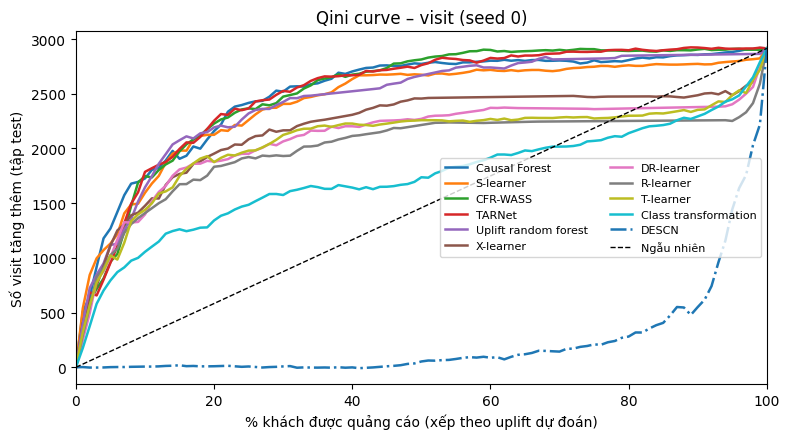

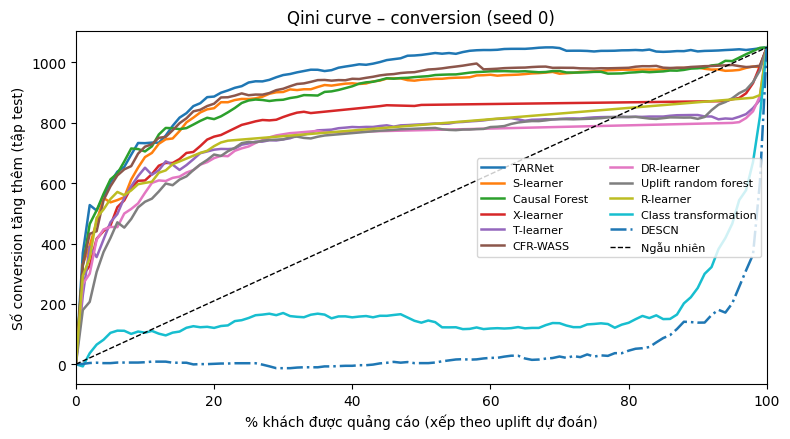

In [ ]:
plt.style.use("default")   # CausalML đổi style matplotlib khi import (chỉ còn 6 màu, đường bị trùng màu); đặt lại mặc định
grid = np.linspace(0, 1, 101)

def load_pred(outcome, name):
    f = np.load(pred_path(outcome, name))
    return f["y"], f["t"], f["score"]

def curve_on_grid(y, t, s):
    x, v = qini_curve(y, t, s)
    return np.interp(grid, x / x[-1], v)

def plot_qini(outcome, names, path):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for k, name in enumerate(names):
        y_, t_, s_ = load_pred(outcome, name)
        ax.plot(grid * 100, curve_on_grid(y_, t_, s_), label=name, linewidth=1.8,
                color=plt.cm.tab10(k % 10), linestyle=["-", "-."][k // 10 % 2])    # 10 màu; hơn 10 đường thì đổi kiểu nét
    end = qini_curve(y_, t_, s_)[1][-1]
    ax.plot(grid * 100, grid * end, color="black", linestyle="--", linewidth=1, label="Ngẫu nhiên")
    ax.set(title=f"Qini curve – {outcome} (seed {SEEDS[0]})", xlim=(0, 100),
           xlabel="% khách được quảng cáo (xếp theo uplift dự đoán)", ylabel=f"Số {outcome} tăng thêm (tập test)")
    ax.legend(fontsize=8, ncol=2)
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()

def plot_decile(outcome, name, path):
    y_, t_, s_ = load_pred(outcome, name)
    dec = uplift_by_decile(y_, t_, s_)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(dec.decile, dec.actual_uplift * 100, yerr=1.96 * dec.actual_uplift_se * 100, capsize=3,
           color="#2a78d6", label="Uplift thực tế (sai số 95%)")
    ax.plot(dec.decile, dec.predicted_uplift * 100, "o", color="black", label="Uplift dự đoán trung bình")
    ax.axhline(0, color="grey", linewidth=1)
    ax.set(title=f"{name}: uplift theo decile – {outcome}", xticks=range(1, 11),
           xlabel="Nhóm 10% khách theo uplift dự đoán (1 = cao nhất)", ylabel="Uplift (điểm %)")
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=200)
    plt.show()

BASELINES = ["S-learner", "T-learner", "X-learner", "R-learner", "DR-learner", "Class transformation",
             "Uplift random forest", "Causal Forest", "TARNet", "CFR-WASS", "DESCN"]
parts = []
for source, path in [("thư viện", os.path.join(RESULTS_DIR, "benchmark_metrics.csv")), ("repo DESCN", metrics_path)]:
    if os.path.exists(path):
        parts.append(pd.read_csv(path).assign(source=source))
    else:
        print("Chưa có", path, "→ chạy notebook tương ứng trước")
full = pd.concat(parts, ignore_index=True)
full = full[full.outcome.isin(OUTCOMES) & full.seed.isin(SEEDS)]

n_fp = full.groupby(["outcome", "seed"])["test_fingerprint"].nunique()
n_src = full.groupby(["outcome", "seed"])["source"].nunique()      # cần kết quả của cả hai notebook mới so được
if (n_fp > 1).any():
    print("CẢNH BÁO: hai notebook dùng tập test khác nhau ở", list(n_fp[n_fp > 1].index),
          "→ kiểm tra N_SAMPLE, SEEDS, VAL_SIZE, TEST_SIZE, DATA_PATH")
elif (n_src < 2).any():
    print("Chưa đối chiếu được mã tập test ở", list(n_src[n_src < 2].index), "vì thiếu kết quả của một notebook")
else:
    print("Hai notebook dùng cùng tập test ở mọi (outcome, seed)")

base = full[full.model.isin(BASELINES)]
summary_full = summarize(base).sort_values(["outcome", "qini_auc"], ascending=[True, False])
display(summary_full)
summary_full.to_csv(os.path.join(RESULTS_DIR, "benchmark_summary_full.csv"))
display(base.groupby(["outcome", "model"])[["n_train", "fit_time_s"]].mean().round(1))

comps = []
for outcome in OUTCOMES:
    means = base[base.outcome == outcome].groupby("model")["qini_auc"].mean().sort_values(ascending=False)
    for other in means.index[1:]:
        comps.append(compare(base, outcome, means.index[0], other))
comparisons_full = pd.DataFrame(comps)
display(comparisons_full.round(4))
comparisons_full.to_csv(os.path.join(RESULTS_DIR, "pairwise_comparisons_full.csv"), index=False)

for outcome in OUTCOMES:
    names = [m for m in base[base.outcome == outcome].groupby("model")["qini_auc"].mean().sort_values(ascending=False).index
             if os.path.exists(pred_path(outcome, m))]
    plot_qini(outcome, names, os.path.join(FIG_DIR, f"qini_full_{outcome}.png"))

## 9. Đối chiếu tiêu chí: cải tiến so với bản gốc
Theo yêu cầu của thầy, cải tiến phải cho kết quả cao hơn bài báo gốc. Tiêu chí: Qini AUC cao hơn bản gốc ở ít nhất 4/5 seed **và** khoảng tin cậy bootstrap 95% của chênh lệch (tập test của seed đầu) nằm hẳn trên 0.
- **Tuần 5 – kiểm tra sớm P:** P so với DESCN gốc trên visit và conversion (minh chứng Hình 5.6). Biết sớm đã có ít nhất một cải tiến đạt tiêu chí hay chưa.
- **Tuần 7 – A3:** A3 so với TARNet gốc trên conversion (Hình 7.3).
- **Tuần 8 – thí nghiệm loại trừ và cỡ mẫu:** các biến thể của A3 (bỏ ràng buộc phễu; λ = 0,2; 0,5; 2) so với TARNet gốc; A3 so với TARNet khi chỉ học trên 25%, 50% tập train (Hình 8.1, một phần Hình 8.2).
- Cuối ô: Qini curve của các cải tiến cạnh bản gốc (`qini_cai_tien_*.png`) và uplift theo decile trên conversion của cải tiến chính (A3 hoặc P) có chênh lệch trung bình lớn nhất cạnh bản gốc của nó (`decile_conversion_*.png`, dùng cho Hình 8.4).

Tiêu chí thành công áp dụng cho A3 với λ = 1 đã định trước. Các biến thể λ chỉ để phân tích độ nhạy: không chọn biến thể tốt nhất trên tập test rồi báo cáo như cải tiến chính (như vậy là chọn trên tập test). Nếu muốn chọn λ, chọn trên tập validation (mục 10).

,outcome,cải tiến,bản gốc,Qini AUC bản gốc,Qini AUC cải tiến,chênh lệch TB,số seed tốt hơn,p-value,CI 95% (seed đầu),đạt tiêu chí
0,visit,P: DESCN cân bằng propensity,DESCN,-0.1142,0.0413,0.1555,5/5,0.0118,[+0.1400; +0.2071],Đạt
1,conversion,P: DESCN cân bằng propensity,DESCN,-0.1843,-0.0695,0.1148,4/5,0.0591,[+0.0229; +0.0859],Đạt


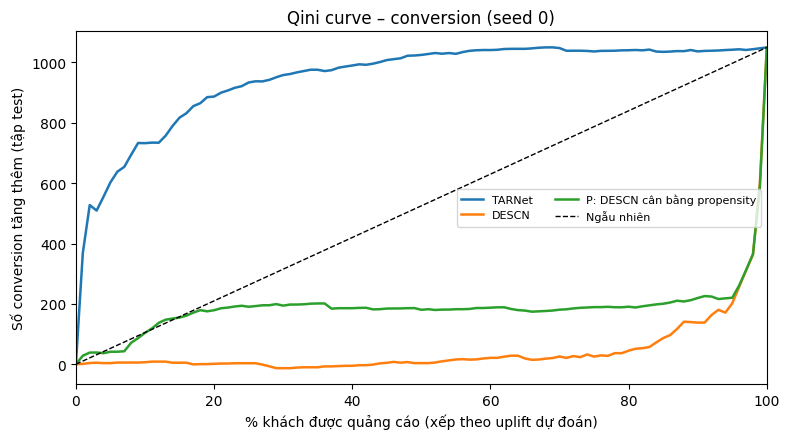

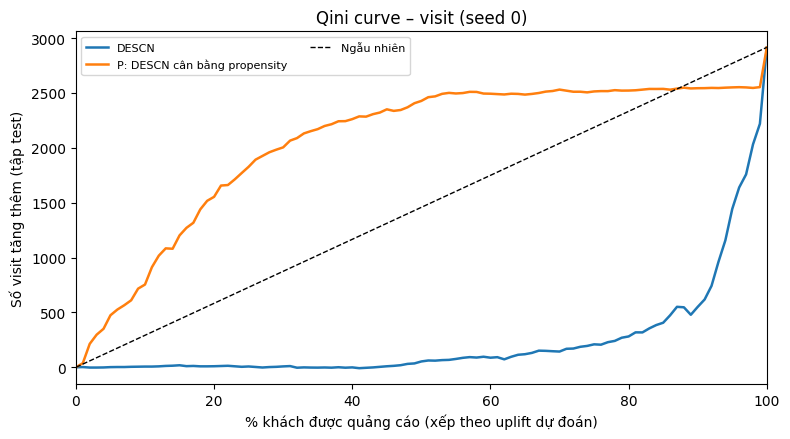

Cải tiến chính có chênh lệch TB lớn nhất trên conversion: P: DESCN cân bằng propensity


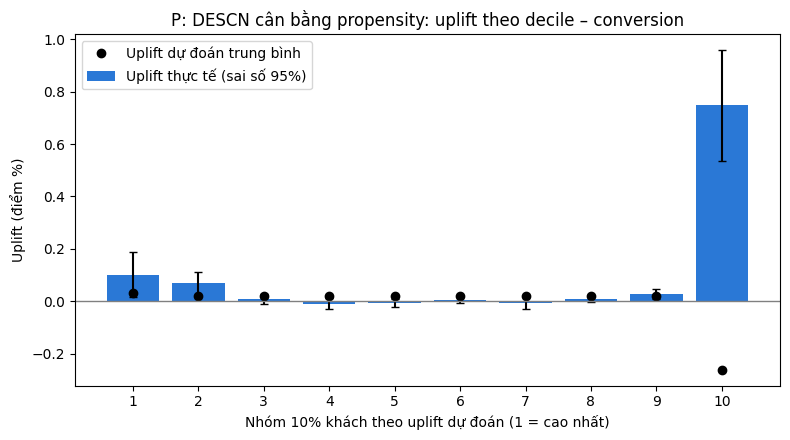

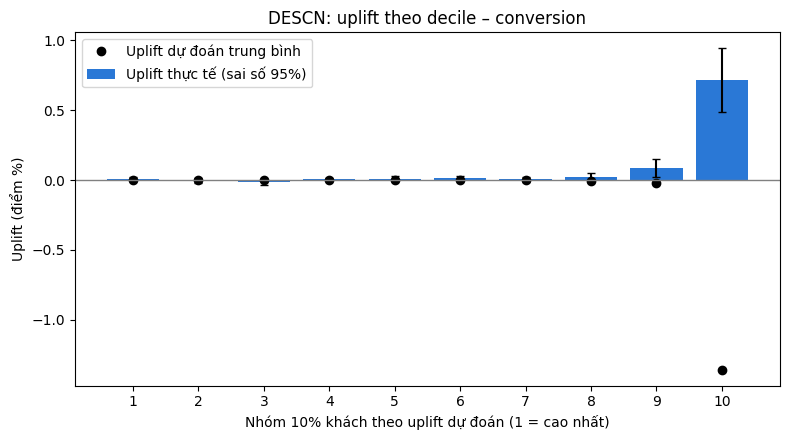

In [ ]:
def improvement_table(res, pairs, n_boot=None):
    # Tiêu chí: cải tiến có Qini AUC cao hơn bản gốc ở ít nhất 80% số seed (4/5)
    # và khoảng tin cậy bootstrap 95% của chênh lệch (tập test, seed đầu) nằm hẳn trên 0
    rows = []
    for outcome, new, base in pairs:
        r = res[res.outcome == outcome]
        if not {new, base} <= set(r.model):
            continue
        c = compare(res, outcome, new, base)
        need = max(1, int(np.ceil(0.8 * c["n_seeds"])))
        row = {"outcome": outcome, "cải tiến": new, "bản gốc": base,
               "Qini AUC bản gốc": r[r.model == base].qini_auc.mean(),
               "Qini AUC cải tiến": r[r.model == new].qini_auc.mean(),
               "chênh lệch TB": c["mean_diff"], "số seed tốt hơn": f"{c['wins_A']}/{c['n_seeds']}",
               "p-value": c["p_value"], "CI 95% (seed đầu)": "chưa có dự đoán"}
        ci_ok = False
        if os.path.exists(pred_path(outcome, new)) and os.path.exists(pred_path(outcome, base)):
            y_, t_, s_new = load_pred(outcome, new)
            _, _, s_base = load_pred(outcome, base)
            _, lo, hi = bootstrap_diff(y_, t_, s_new, s_base, n_boot=n_boot or N_BOOT)
            row["CI 95% (seed đầu)"] = f"[{lo:+.4f}; {hi:+.4f}]"
            ci_ok = lo > 0
        row["đạt tiêu chí"] = "Đạt" if (c["wins_A"] >= need and ci_ok) else "Chưa đạt"
        rows.append(row)
    return pd.DataFrame(rows)

nets_res = pd.read_csv(metrics_path)
nets_res = nets_res[nets_res.outcome.isin(OUTCOMES) & nets_res.seed.isin(SEEDS)]
pairs = [(o, "P: DESCN cân bằng propensity", "DESCN") for o in OUTCOMES]
if TUAN >= 7:
    pairs += [("conversion", "A3: TARNet + phễu", "TARNet")]
if TUAN >= 8:
    pairs += [("conversion", n, "TARNet") for n in ["A3 không nhân phễu", "A3 (λ = 0,2)", "A3 (λ = 0,5)", "A3 (λ = 2)"]]
    pairs += [("conversion", f"A3: TARNet + phễu [{f:.0%} train]", f"TARNet [{f:.0%} train]") for f in SIZE_FRACTIONS]
crit = improvement_table(nets_res, pairs)
display(crit.round(4))
crit.to_csv(os.path.join(RESULTS_DIR, "improvement_check_nets.csv"), index=False)

for outcome, names in [("conversion", ["TARNet", "A3: TARNet + phễu", "A3 không nhân phễu", "DESCN",
                                       "P: DESCN cân bằng propensity"]),
                       ("visit", ["DESCN", "P: DESCN cân bằng propensity"])]:
    names = [n for n in names if outcome in OUTCOMES and os.path.exists(pred_path(outcome, n))]
    if len(names) > 1:
        plot_qini(outcome, names, os.path.join(FIG_DIR, f"qini_cai_tien_{outcome}.png"))

# Uplift theo decile trên conversion: cải tiến chính có chênh lệch TB lớn nhất và bản gốc của nó (Hình 8.4)
if len(crit):
    main = crit[(crit.outcome == "conversion") & crit["cải tiến"].isin(["A3: TARNet + phễu", "P: DESCN cân bằng propensity"])]
    if len(main):
        best = main.loc[main["chênh lệch TB"].idxmax()]
        print("Cải tiến chính có chênh lệch TB lớn nhất trên conversion:", best["cải tiến"])
        for name in [best["cải tiến"], best["bản gốc"]]:
            if os.path.exists(pred_path("conversion", name)):
                plot_decile("conversion", name, os.path.join(FIG_DIR, f"decile_conversion_{slug(name)}.png"))

## 10. Ghi chú
- **Chọn tham số (nếu cần):** chạy `run_repo_model` với tập validation thay cho tập test (ghi `X[idx_va]` ra một file npz riêng), so sánh các giá trị bằng `evaluate`, rồi mới chạy trên tập test với giá trị đã chọn. Không chọn trên tập test.
- **Giải thích được phần sửa:** mỗi dòng trong `results/descn_cai_tien.diff` đều phải giải thích được khi bảo vệ (vì sao sửa, cờ nào bật nó).
- Kết quả không đạt tiêu chí vẫn báo cáo đúng như thật, kèm phân tích từ thí nghiệm loại trừ.